# ARES Flight Computer Test Flight 
## (Cherrybomb 10k Test flight May 4,2025)

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
# Load the IREC test launch CSV as a pandas DataFrame
data = pd.read_csv('data/irec-10k-test-flight-data.csv')

# Start at zero seconds
data['timestamp_utc'] = data['timestamp_utc'] - data['timestamp_utc'][0] 

# Correct longitude data
degrees = np.floor(data['longitude_deg'])
incorrect_minutes = (data['longitude_deg'] - degrees) * 60
n = np.floor(incorrect_minutes / 100)
correct_minutes = incorrect_minutes - 100 * n
data['longitude_deg'] = degrees + correct_minutes / 60

data.head()



,timestamp_utc,fsm_mode,gps_fix,gps_antenna_status,heading_deg,target_heading_deg,h_speed_m_s,v_speed_m_s,latitude_deg,longitude_deg,...,bno_lin_y,bno_lin_z,bno_grav_x,bno_grav_y,bno_grav_z,bno_quat_w,bno_quat_x,bno_quat_y,bno_quat_z,flight_id
0,0.0,0,2,0,238.56,NaN,0.0103,NaN,46.410557,-134.014633,...,3.70,-8.86,1.93,-3.70,8.86,0.0523,-0.1115,0.1880,-0.9744,ARES-01
1,1.0,0,2,0,238.56,NaN,0.0051,NaN,46.410557,-134.014633,...,3.70,-8.86,1.93,-3.70,8.86,0.0523,-0.1115,0.1880,-0.9744,ARES-01
2,2.0,0,2,0,238.56,NaN,0.0103,NaN,46.410557,-134.014633,...,3.70,-8.86,1.93,-3.70,8.86,0.0523,-0.1115,0.1880,-0.9744,ARES-01
3,3.0,0,2,0,238.56,NaN,0.0051,NaN,46.410557,-134.014633,...,3.54,-8.88,2.16,-3.53,8.88,0.0644,-0.1247,0.1767,-0.9742,ARES-01
4,4.0,0,2,0,238.56,NaN,0.2469,NaN,46.410557,-134.014633,...,1.73,-8.88,3.77,-1.73,8.88,-0.2151,-0.1726,0.1317,-0.9521,ARES-01


In [5]:
def moving_average_same_length(data, window_size):
    # Pad data symmetrically at both ends
    pad_size = window_size // 2
    padded = np.pad(data, (pad_size, pad_size), mode='reflect')
    
    # Apply convolution with a uniform window
    weights = np.ones(window_size) / window_size
    smoothed = np.convolve(padded, weights, mode='valid')
    
    return smoothed

GPS Fix Loss Time: 20.0


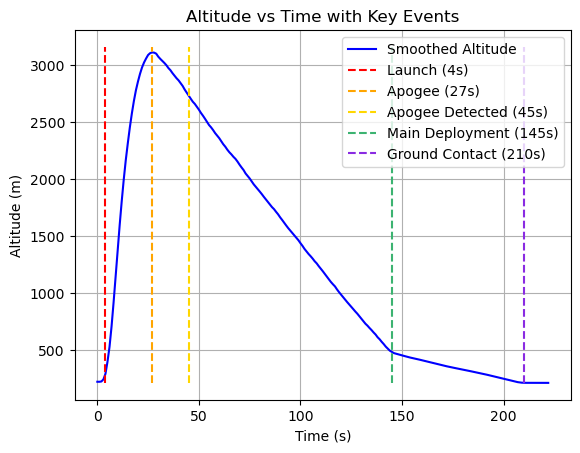

In [ ]:
data['smoothed_altitude'] = moving_average_same_length(data['altitude_m'], window_size=5)

plt.figure()
# plt.plot(data['timestamp_utc'], data['altitude_m'], 'b-', label='Altitude')
plt.plot(data['timestamp_utc'], data['smoothed_altitude'], 'b-', label='Smoothed Altitude')

# Identify key events
launch_time = data['timestamp_utc'][data['altitude_m'] > data['altitude_m'][0] + 10].iloc[0]  # First non-zero altitude
apogee_time = data['timestamp_utc'][data['altitude_m'].idxmax()]    # Time of maximum altitude
apogeet_detected = data['timestamp_utc'][data['fsm_mode'] == 1].iloc[0]

gps_fix_loss = data['timestamp_utc'][data['gps_fix'] == 404].iloc[0]  # First instance of GPS fix loss
gps_fix_return = data['timestamp_utc'][(data['gps_fix'] == 2) & (data['timestamp_utc'] > gps_fix_loss)].iloc[0]  # First instance of GPS fix return
print("GPS Fix Loss Time:", gps_fix_loss) 

# Calculate descent rate (negative of altitude derivative)
descent_rate = -data['smoothed_altitude'].diff(/)  
main_deployment = data['timestamp_utc'][(descent_rate < 12) & (data['apogee_detected'] == 1)].iloc[0]  # First instance of descent rate change
grounded_time = data['timestamp_utc'][(descent_rate < 1) & (data['apogee_detected'] == 1)].iloc[0]  # First instance of ground contact

# Plot altitude graph with vertical lines
plt.vlines(launch_time, ymin=data['altitude_m'].min(), ymax=data['altitude_m'].max(), color='r', linestyle='--', label=f'Launch ({int(launch_time)}s)')
plt.vlines(apogee_time, ymin=data['altitude_m'].min(), ymax=data['altitude_m'].max(), color='orange', linestyle='--', label=f'Apogee ({int(apogee_time)}s)')
plt.vlines(apogeet_detected, ymin=data['altitude_m'].min(), ymax=data['altitude_m'].max(), color='gold', linestyle='--', label=f'Apogee Detected ({int(apogeet_detected)}s)')
plt.vlines(main_deployment, ymin=data['altitude_m'].min(), ymax=data['altitude_m'].max(), color='mediumseagreen', linestyle='--', label=f'Main Deployment ({int(main_deployment)}s)')
plt.vlines(grounded_time, ymin=data['altitude_m'].min(), ymax=data['altitude_m'].max(), color='blueviolet', linestyle='--', label=f'Ground Contact ({int(grounded_time)}s)')
# plt.vlines(gps_fix_loss, ymin=data['altitude_m'].min(), ymax=data['altitude_m'].max(), color='k', linestyle='--', label='GPS Fix Loss')
# plt.vlines(gps_fix_return, ymin=data['altitude_m'].min(), ymax=data['altitude_m'].max(), color='c', linestyle='--', label='GPS Fix Return')

# Add labels and legend
plt.xlabel('Time (s)')
plt.ylabel('Altitude (m)')
plt.legend()
plt.grid()
plt.title('Altitude vs Time with Key Events')
plt.show()

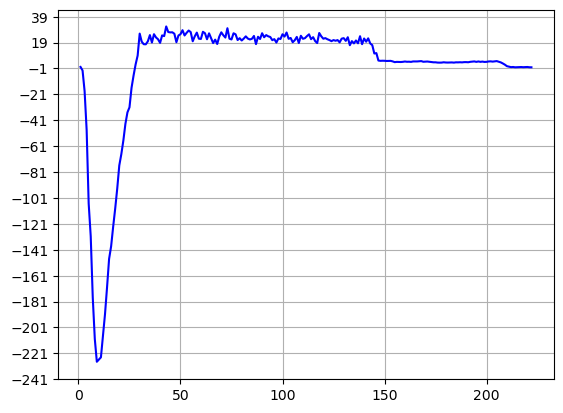

In [54]:
plt.figure()
plt.plot(data['timestamp_utc'], descent_rate, 'b-', label='Descent Rate')
# Add more y-axis ticks for better readability
import numpy as np
ymin, ymax = plt.ylim()
plt.yticks(np.arange(np.floor(ymin), np.ceil(ymax)+1, 20))  # Tick every 2 units
plt.grid()

Actual apogee at: 27.0s
Apogee trigger at: 45.0s
Difference: 18.0s


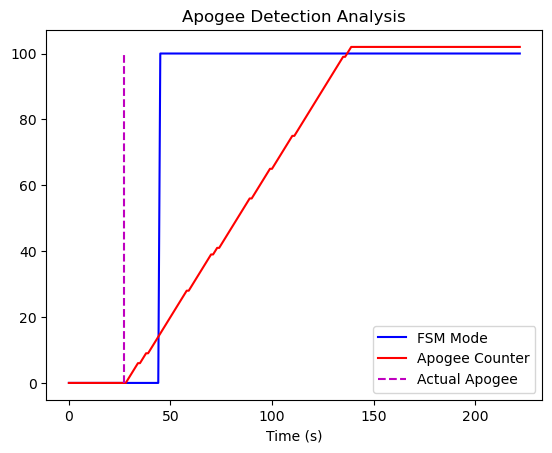

In [25]:
plt.figure()
plt.plot(data['timestamp_utc'], data['fsm_mode']*100, 'b-', label='FSM Mode')
plt.plot(data['timestamp_utc'], data['apogee_counter'], 'r-', label='Apogee Counter')
plt.vlines(apogee_time, ymin=0, ymax=100, color='m', linestyle='--', label='Actual Apogee')
plt.legend()
plt.xlabel('Time (s)')
plt.title('Apogee Detection Analysis')
print(f"Actual apogee at: {apogee_time}s")
print(f"Apogee trigger at: {apogeet_detected}s")
print(f"Difference: {apogeet_detected - apogee_time}s")

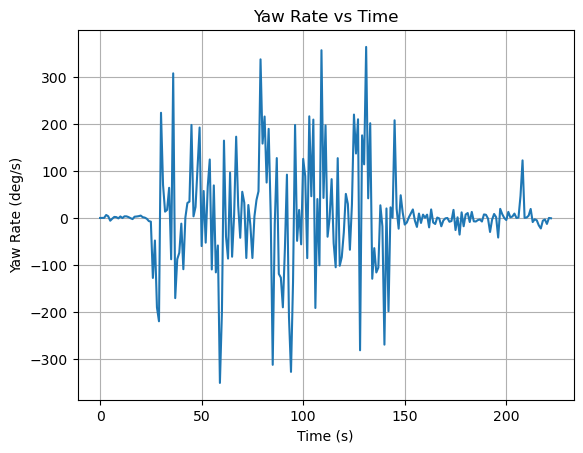

In [97]:
plt.figure()
plt.plot(data['timestamp_utc'], data['yaw_rate'], label='Yaw Rate')
plt.title('Yaw Rate vs Time')
plt.xlabel('Time (s)')
plt.ylabel('Yaw Rate (deg/s)')
# plt.ylim(-50, 50)
plt.grid()

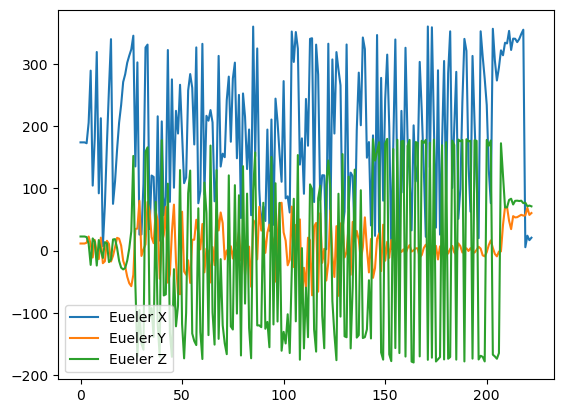

In [8]:
plt.figure()
plt.plot(data['timestamp_utc'], data['bno_eul_x'], label='Eueler X')
plt.plot(data['timestamp_utc'], data['bno_eul_y'], label='Eueler Y')
plt.plot(data['timestamp_utc'], data['bno_eul_z'], label='Eueler Z')
plt.legend()

In [9]:
plt.figure()


<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [10]:
import plotly.graph_objects as go

# Sample data (replace with your actual data)
latitudes = data['latitude_deg'].tolist()
longitudes = data['longitude_deg'].tolist()
altitudes = data['altitude_m'].tolist()

# Create the 3D scatter plot
fig = go.Figure(data=[go.Scatter3d(
    x=longitudes,
    y=latitudes,
    z=altitudes,
    mode='markers+lines',  # Show both markers and lines
    marker=dict(
        size=5,
        color=altitudes,  # Color points by altitude
        colorscale='Viridis'  # Choose a colorscale
    ),
    line=dict(
        width=2
    )
)])

# Update layout for better visualization
fig.update_layout(
    title='3D Trajectory',
    scene=dict(
        xaxis_title='Longitude',
        yaxis_title='Latitude',
        zaxis_title='Altitude (m)',
        aspectmode='auto' # automatically adjusts axes to data range
    ),
    margin=dict(l=0, r=0, b=0, t=40)
)

fig.show()